In [1]:
import numpy as np
import matplotlib.pyplot as plt

class Source:
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def generate_directions(self, E: float) -> np.ndarray:
        """Разыгрывает случайное число фотонов (Пуассон) и их направления."""
        N = np.random.poisson(lam=self.Y * E)
        phi = np.random.uniform(0, 2 * np.pi, size=N)
        cos_theta = np.random.uniform(-1.0, 1.0, size=N)
        sin_theta = np.sqrt(1.0 - cos_theta**2)
        
        nx = sin_theta * np.cos(phi)
        ny = sin_theta * np.sin(phi)
        nz = cos_theta
        return np.column_stack((nx, ny, nz))


class Detector:
    def __init__(self, R: float = 2.0, N: int = 40, r: float = 0.1, a: float = 0.5, 
                 attenuation_length: float | None = 8.0):
        self.R = float(R)
        self.N = int(N)
        self.r = float(r)
        self.a = float(a)
        self.attenuation_length = attenuation_length
        self.pmt_coords = self._generate_pmt_positions()
        
    def _generate_pmt_positions(self) -> np.ndarray:
        indices = np.arange(0, self.N, dtype=float) + 0.5
        z = self.R * (1 - 2 * indices / self.N)
        rho = np.sqrt(self.R**2 - z**2)
        golden_angle = np.pi * (3.0 - np.sqrt(5.0))
        theta = golden_angle * indices
        x = rho * np.cos(theta)
        y = rho * np.sin(theta)
        return np.column_stack((x, y, z))

    def generate_photoelectrons(self, n_hits: int | np.ndarray = 1) -> int | np.ndarray:
        return np.random.poisson(lam=self.a * n_hits)

    def detect_photons(self, origin: np.ndarray, directions: np.ndarray) -> np.ndarray:
        origin = np.asarray(origin, dtype=float)
        
        # Находим расстояние t до пересечения со сферой
        b = np.sum(directions * origin, axis=1)
        c = np.sum(origin**2) - self.R**2
        t = -b + np.sqrt(b**2 - c)
        
        # Точки пересечения со сферой
        hit_points = origin + t[:, None] * directions
        
        # Учет экспоненциального затухания света с длиной L = attenuation_length
        if self.attenuation_length is not None:
            survival_prob = np.exp(-t / self.attenuation_length)
            survived = np.random.uniform(0.0, 1.0, size=len(t)) < survival_prob
            hit_points = hit_points[survived]
        
        # Подсчет попаданий выживших фотонов в каждый ФЭУ
        hits_per_pmt = np.zeros(self.N, dtype=int)
        for i, pmt_center in enumerate(self.pmt_coords):
            distances = np.linalg.norm(hit_points - pmt_center, axis=1)
            hits_per_pmt[i] = np.sum(distances <= self.r)
            
        return self.generate_photoelectrons(hits_per_pmt)


def simulate_events(detector: Detector, source: Source, E: float, origin: np.ndarray, n_events: int = 500) -> np.ndarray:
    """Моделирует n_events событий и возвращает массив полных собранных зарядов Q."""
    charges = []
    for _ in range(n_events):
        dirs = source.generate_directions(E)
        pe_counts = detector.detect_photons(origin, dirs)
        charges.append(np.sum(pe_counts))
    return np.array(charges)

z = -1.8 м | <Q> без затухания =  102.9 ф.э. | <Q> с затуханием (L=8м) =   85.0 ф.э.
z = -1.5 м | <Q> без затухания =  121.6 ф.э. | <Q> с затуханием (L=8м) =  101.0 ф.э.
z = -1.0 м | <Q> без затухания =  124.2 ф.э. | <Q> с затуханием (L=8м) =   99.6 ф.э.
z = -0.5 м | <Q> без затухания =  124.6 ф.э. | <Q> с затуханием (L=8м) =   97.3 ф.э.
z =  0.0 м | <Q> без затухания =  125.1 ф.э. | <Q> с затуханием (L=8м) =   97.5 ф.э.
z =  0.5 м | <Q> без затухания =  124.9 ф.э. | <Q> с затуханием (L=8м) =   98.1 ф.э.
z =  1.0 м | <Q> без затухания =  124.9 ф.э. | <Q> с затуханием (L=8м) =  100.2 ф.э.
z =  1.5 м | <Q> без затухания =  121.9 ф.э. | <Q> с затуханием (L=8м) =  101.6 ф.э.
z =  1.8 м | <Q> без затухания =  102.6 ф.э. | <Q> с затуханием (L=8м) =   85.0 ф.э.


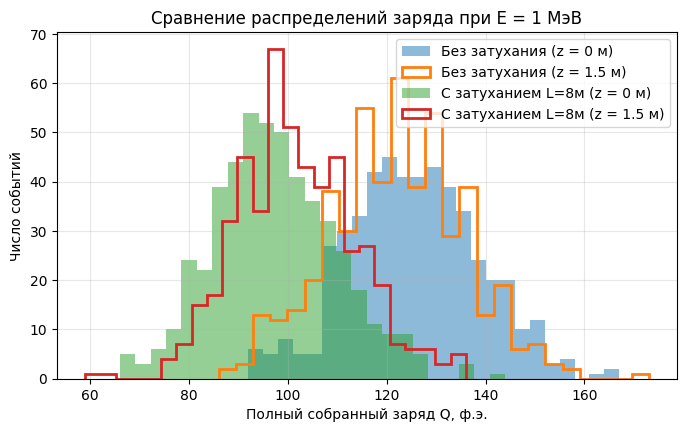

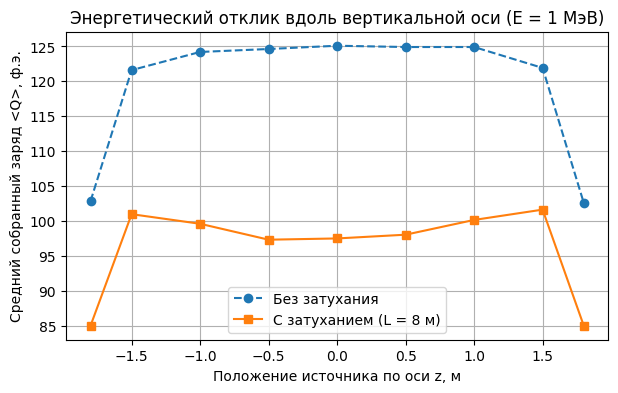

In [2]:
source = Source(Y=10000)

# Создаем два детектора: с затуханием (L = 8 м) и без затухания (None)
det_att = Detector(R=2.0, N=40, r=0.1, a=0.5, attenuation_length=8.0)
det_no_att = Detector(R=2.0, N=40, r=0.1, a=0.5, attenuation_length=None)

z_positions = [-1.8, -1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5, 1.8]

mean_with_att = []
mean_without_att = []

# Сохраним распределения в центре (z = 0) и у края (z = 1.5 м) для гистограммы
distributions_att = {}
distributions_no_att = {}

for z in z_positions:
    origin = np.array([0.0, 0.0, z])
    
    q_att = simulate_events(det_att, source, E=1.0, origin=origin, n_events=500)
    q_no_att = simulate_events(det_no_att, source, E=1.0, origin=origin, n_events=500)
    
    mean_with_att.append(np.mean(q_att))
    mean_without_att.append(np.mean(q_no_att))
    
    if z in [0.0, 1.5]:
        distributions_att[z] = q_att
        distributions_no_att[z] = q_no_att
        
    print(f"z = {z:4.1f} м | <Q> без затухания = {np.mean(q_no_att):6.1f} ф.э. | "
          f"<Q> с затуханием (L=8м) = {np.mean(q_att):6.1f} ф.э.")

# График 1: Сравнение распределений собранного заряда (гистограммы)
plt.figure(figsize=(8, 4.5))
plt.hist(distributions_no_att[0.0], bins=25, alpha=0.5, label='Без затухания (z = 0 м)')
plt.hist(distributions_no_att[1.5], bins=25, histtype='step', lw=2, label='Без затухания (z = 1.5 м)')
plt.hist(distributions_att[0.0], bins=25, alpha=0.5, label='С затуханием L=8м (z = 0 м)')
plt.hist(distributions_att[1.5], bins=25, histtype='step', lw=2, label='С затуханием L=8м (z = 1.5 м)')
plt.xlabel('Полный собранный заряд Q, ф.э.')
plt.ylabel('Число событий')
plt.title('Сравнение распределений заряда при E = 1 МэВ')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# График 2: Зависимость среднего собранного заряда от координаты z
plt.figure(figsize=(7, 4))
plt.plot(z_positions, mean_without_att, 'o--', label='Без затухания')
plt.plot(z_positions, mean_with_att, 's-', label='С затуханием (L = 8 м)')
plt.xlabel('Положение источника по оси z, м')
plt.ylabel('Средний собранный заряд <Q>, ф.э.')
plt.title('Энергетический отклик вдоль вертикальной оси (E = 1 МэВ)')
plt.legend()
plt.grid(True)
plt.show()

### Выводы по Задаче 6:
1. **Влияние затухания на величину собранного заряда:**
   Учет экспоненциального затухания света ($L = 8$ м) приводит к снижению полного собранного заряда. Для источника в центре детектора ($z = 0$) все фотоны проходят путь $t = R = 2$ м, поэтому выживает доля фотонов $e^{-R/L} = e^{-2/8} \approx 0.78$, и средний заряд уменьшается со $\approx 125$ ф.э. (без затухания) до $\approx 97$ ф.э. (с затуханием).

2. **Зависимость отклика от положения источника вдоль оси $z$:**
   * **Без затухания:** распределение и среднее значение собранного заряда ($\langle Q \rangle \approx 125$ ф.э.) практически не зависят от координаты $z$.
   * **С затуханием:** появляется зависимость отклика от координаты — по мере смещения источника от центра ($z = 0$) к краям детектора ($|z| \to 1.8$ м) средний собранный заряд **увеличивается** (с $\approx 97$ ф.э. до $\approx 105–107$ ф.э.). Это объясняется тем, что вблизи стенки большая доля фотонов попадает в ближайшие ФЭУ, проходя малый путь в сцинтилляторе и испытывая меньшее поглощение.